## **Unit FoV Visualisation  |  Catalogue VS Reconstructed Sources**

In [66]:
from bisect import bisect
from pathlib import Path
from typing import Any, NamedTuple, Optional

import numpy as np
from numpy.typing import NDArray
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from astropy.io import fits

from bloodmoon.coords import equatorial2shift, shift2angle, angle2shift, shift2pos
from bloodmoon.io import simulation_files
from bloodmoon.mask import CodedMaskCamera, codedmask
from bloodmoon.mask import count, decode, variance, snratio
from bloodmoon.images import argmax
from bloodmoon.optim import model_sky
import darksun as ds
from darksun.data import Log, DataLoader, CatalogueLoader
from darksun.types import LogEntry

from IROSrec.handle import config_dirpaths
import imgmaker as mgm

plt.rcdefaults()

RCPARAMS = {
    'axes.formatter.limits': (-3, 3),
    'savefig.bbox': 'tight',
}
mpl.rcParams.update(RCPARAMS)
ds.show.set_figures_darkbkg()

In [67]:
MASK_FITS: str = 'mask_NTHT_20250725.fits'
UPS_X, UPS_Y = 2, 1
hide_bulk_els_y: float = 1.5   # [mm]

SKYFIELD: str = 'GalacticCentre'
DATA_FITS: str = 'galctr_rxte-sax_mask_050_1040x17_2-50keV_1ks_mask25'

RUN_ID: str = 'GC_smoothed_rec_1ks_2-50keV_mask25'
DATASET: str = 'reconstructed'

# ID_CAMERA: str = 'cam1a'
ID_CAMERA: str = 'cam1b'

VIGNETTING: bool = True
PSFY: bool = mgm.config_psfy_flag(DATASET)

In [68]:
def extract_cam_data(
    camID: str,
    dl_path: str,
    cl_path: str,
    src_db_path: str,
    **dl_kws,
) -> tuple[DataLoader, CatalogueLoader, Log]:
    sdl_cam = ds.get_data(dl_path, **dl_kws)
    cat_cam = ds.get_catalogue(cl_path)
    _idx = 0 if camID[-1] == 'a' else 1
    log_cam = ds.load_database(src_db_path)[_idx]
    return sdl_cam, cat_cam, log_cam


MASK_PATH, SIMUL_DATA_PATH, SAVE_PATH = config_dirpaths(
    mask=MASK_FITS,
    skyfield=SKYFIELD,
    simul=DATA_FITS,
    runID=RUN_ID,
)
OUT_RESULTS_PATH = mgm.config_savedata_to()
wfm: CodedMaskCamera = codedmask(MASK_PATH, UPS_X, UPS_Y, hide_bulk_els_y=hide_bulk_els_y)
filepaths: dict[str, dict[str, Path]] = simulation_files(SIMUL_DATA_PATH)

sdl_cam, cat_cam, log_cam = extract_cam_data(
    camID=ID_CAMERA,
    dl_path=filepaths[ID_CAMERA][DATASET],
    cl_path=filepaths[ID_CAMERA]["sources"],
    src_db_path=f"{SAVE_PATH}/IROS_sources_db.fits",
)

# Loading data...
# Loading completed!


In [69]:
# from bloodmoon.types import CoordEquatorial

# exclude_coords = CoordEquatorial(244.98, -15.64)

# sdl_cam, cat_cam, log_cam = extract_cam_data(
#     camID=ID_CAMERA,
#     dl_path=filepaths[ID_CAMERA][DATASET],
#     cl_path=filepaths[ID_CAMERA]["sources"],
#     src_db_path=f"{SAVE_PATH}/IROS_sources_db.fits",
#     coords=exclude_coords,
# )

In [70]:
class Source(NamedTuple):
    """Source info (ID, instr. local-frame coords [deg], flux [ph/cm2/s])."""
    ID: str
    angle_x: float
    angle_y: float
    flux: float

def extract_idxs(bins: tuple[NDArray, NDArray], coords: tuple[float, float]) -> tuple[int, int]:
    """Converts source coords to nearest discrete pixel indexes in relative binning array."""
    return bisect(bins[0], coords[0]) - 1, bisect(bins[1], coords[1]) - 1

def find_boxmax(sky: NDArray, centre: tuple[int, int], boxsize: int = 5) -> tuple[int, int]:
    """Finds the argmax of given sky in a box centered around `pos`."""
    rcut, ccut = map(lambda idx: slice(idx - boxsize, idx + boxsize + 1), centre)
    p, q = centre
    n, m = argmax(sky[rcut, ccut])
    return p - boxsize + n, q - boxsize + m

def subtract_previous(
    camera: CodedMaskCamera,
    log: Log,
    up_to_src_idx: int,
    true_sky: NDArray,
    vignetting: bool = True,
    psfy: bool = True,
) -> NDArray:
    """Subtracts sources previous to IROS src index in `log`."""
    sky = true_sky.copy()
    for idx in range(up_to_src_idx):
        modelled = model_sky(
            camera, log.log['shift_x'][idx], log.log['shift_y'][idx],
            log.log['fluence'][idx], vignetting=vignetting, psfy=psfy
        )
        sky -= modelled
    return sky

def equatorial2angle(
    sdl: DataLoader,
    camera: CodedMaskCamera,
    ra: float,
    dec: float,
) -> tuple[float, float]:
    """Converts RA/Dec coords to camera local-frame angular coords."""
    shifts = equatorial2shift(sdl, camera, ra, dec)
    return tuple(shift2angle(camera, s) for s in shifts)

In [71]:
def retrieve_detectable_srcs(
    camera: CodedMaskCamera,
    sdl: DataLoader,            # NOTE: here is DataLoader, but only needs camera pointings
    catalogue: CatalogueLoader,
    exposure: float,
) -> tuple[Source, ...]:
    """Retrieves all detectable sources during a given exposure within the FoV of a LEM-X camera."""
    # extract min detectable flx @ 5sigma in given exposure with sensitivity map in Evangelista+2026
    # (Fig 8, pag 16) @ https://link.springer.com/content/pdf/10.1007/s10686-026-10047-x.pdf
    #   * min(sensitivity map) returns the flx @ 5sigma for an on-axis source
    #   * 1 s / exposure is the conversion factor accounting for the exposure (sqrt due to SNR computation)
    #   * 4.5487 ph/cm2/s is the Crab avg emitted flux in 2-50 keV
    # NOTE: the sensitivity map is expressed in mCrab, hence the 1e3 factor
    sens_map = fits.getdata('./sensitivity_map_mask_050_1040x17_20260129_Crab20260204_Camb_2cameras_min_upsx_3_maxf.fits')
    sens_map = np.clip(sens_map, a_min=None, a_max=5000) # clip @ 5000 mCrab to avoid artefacts
    sens_map = sens_map * 4.5487 / 1e3 * np.sqrt(1 / exposure)
    # remove non-detectable sources to reduce comp cost
    _, unique_idxs = np.unique(catalogue.DLdata['ID'], return_index=True)
    srcs = catalogue.DLdata[unique_idxs]
    over_min_flx = srcs['FLUX'] > sens_map.min()
    srcs = srcs[over_min_flx]
    if not len(srcs):
        print(f'No source above min flux threshold in a {exposure} s exposure...')
        return ()

    # now we check each source based on position within FoV and emitted flux
    fake_srcs = ['-1', 'gctr_diffuse']
    bins_y, bins_x = map(lambda s: np.linspace(-45, 45, s), sens_map.shape)
    detectable = []
    for src in srcs:
        if src['ID'] not in fake_srcs:
            angle_x, angle_y = equatorial2angle(sdl, camera, src['RA'], src['DEC'])
            pos = extract_idxs((bins_y, bins_x), (angle_y, angle_x))
            if src['FLUX'] >= sens_map[*pos]:
                detectable.append(Source(src['ID'], float(angle_x), float(angle_y), float(src['FLUX'])))
    if not len(detectable):
        print(f'No detectable sources in a {exposure} s exposure...')
        return ()
    return tuple(detectable)

def get_detectable_srcs_log(sources: tuple[Source, ...]) -> Log:
    """Builds the Log container for all detectable sources within camera FoV."""
    params: tuple[LogEntry, ...] = (
        LogEntry('ID', 'A20', ''),
        LogEntry('angle_x', 'f16', 'deg'),
        LogEntry('angle_y', 'f16', 'deg'),
    )
    log: Log = ds.create_log(params)
    log.add_entry_values('ID', [s.ID for s in sources])
    log.add_entry_values('angle_x', [s.angle_x for s in sources])
    log.add_entry_values('angle_y', [s.angle_y for s in sources])
    return log

def get_detectable_srcs_data(log, camera, sdl) -> ...:
    """Extracts detectable sources data."""
    return

In [72]:
def find_tick_val(ticks: NDArray, trg_vals: NDArray, atol: float = 1e-4) -> NDArray:
    """Finds the idxs inside `ticks` relative to given values `trg_vals`."""
    trg_idxs: list[int] = []
    for v in trg_vals:
        idx = np.argwhere(np.isclose(ticks, v, atol=atol))
        if idx.size > 0: trg_idxs.append(idx[0, 0])
    return np.array(trg_idxs)

def set_phase(x: NDArray) -> NDArray:
    """Centers `x` values around zero."""
    return np.arange(len(x) + 1) - len(x) // 2 - 0.5

def get_slices(*arrs: NDArray) -> tuple[tuple[NDArray, ...], tuple[NDArray, ...]]:
    n, m = arrs[0].shape
    xslice, yslice = zip(*tuple((c[(n - 1) // 2, :], c[:, (m - 1) // 2]) for c in arrs))
    return xslice, yslice

In [ ]:
def show_skyfield_map(
    camera: CodedMaskCamera,
    log: Log,
    show_IDs: bool = True,
    rec_log: Optional[Log] = None,
    save_to: Optional[str | Path] = None,
    save_options: Optional[dict[str, Any]] = None,
    camID: Optional[str] = None,
    **fig_kws,
) -> None:
    """Displays detectable (and optionally reconstructed) sources in the camera FoV."""
    _skyx, _skyy = camera.bins_sky
    skyx, skyy = map(
        lambda x: shift2angle(camera, x),
        (_skyx, _skyy),
    )
    SETUP = {
        'x': 'angle_x',
        'y': 'angle_y',
        'xlabel': '$\\theta_{fine}$ [deg]',
        'ylabel': '$\\theta_{coarse}$ [deg]',
        'title': f'Local Frame SkyMap Grid' + f' - {camID}' if camID else '',
        'title_fs': 16,
        'lbl_fs': 14,

        'color': '#120E16',
        'txt_fs': 7,
        'txt_color': 'white',
        'rot': 35,
        'alpha': 0.75,

        'xline': ((skyx[0], skyx[-1]), (0, 0)),
        'yline': ((0, 0), (skyy[0], skyy[-1])),

        'xlim': (skyx[0], skyx[-1]),
        'ylim': (skyy[0], skyy[-1]),
    }
    add_rec_srcs_info = rec_log is not None

    fig, ax = plt.subplots(1, 1, tight_layout=True, **fig_kws)
    ax.set_title(SETUP['title'], fontsize=SETUP['title_fs'], pad=15)
    ax.set_xlabel(xlabel=SETUP['xlabel'], fontsize=SETUP['lbl_fs'])
    ax.set_ylabel(ylabel=SETUP['ylabel'], fontsize=SETUP['lbl_fs'])
    for line in ('xline', 'yline'):
        ax.plot(*SETUP[line], color="#4E4E4E", linestyle='--', linewidth=0.6, alpha=0.5)

    scatter_factory = {'c': SETUP['color'], 'alpha': SETUP['alpha'], 's': 15}
    ax.scatter(
        log.log[SETUP['x']], log.log[SETUP['y']], edgecolor='DeepSkyBlue', label='detectable', **scatter_factory,
    )
    if add_rec_srcs_info:
        ax.scatter(
            rec_log.log[SETUP['x']], rec_log.log[SETUP['y']], edgecolor='Orange', label='reconstr.', **scatter_factory,
        )

    if show_IDs:
        for name, x, y in zip(
            log.log['ID'],
            log.log[SETUP['x']],
            log.log[SETUP['y']],
        ):
            ax.text(x + 0.475, y + 0.385, name, fontsize=SETUP['txt_fs'], color=SETUP['txt_color'], rotation=SETUP['rot'])
        
        if add_rec_srcs_info:
            for name, x, y in zip(
                rec_log.log['ID'],
                rec_log.log[SETUP['x']],
                rec_log.log[SETUP['y']],
            ):
                if name not in log.log['ID']:
                    ax.text(x + 0.475, y + 0.385, name, fontsize=SETUP['txt_fs'], color=SETUP['txt_color'], rotation=SETUP['rot'])

    ax.set_xlim(SETUP['xlim']); ax.set_ylim(SETUP['ylim'])
    ax.xaxis.set_ticks_position('both'); ax.yaxis.set_ticks_position('both')
    ax.tick_params(which='both', direction='in', width=1.5, length=4 if 'major' else 2.5, labelsize=SETUP['lbl_fs'])
    if add_rec_srcs_info:
        ax.legend(loc='best')

    if save_to is not None:
        save_options_ = save_options or {}
        fig.savefig(save_to, **save_options_)
    
    plt.show()
    return


def show_missing_srcs(
    camera: CodedMaskCamera,
    srcs_log: Log,
    rec_log: Log,
    skymap: NDArray,
    varmap: NDArray,
    crp: tuple[int, int],
    subtract_upto: Optional[int] = None,
    save_to: Optional[str | Path] = None,           # NOTE: path to directory
    frmt: str = 'pdf',
    save_options: Optional[dict[str, Any]] = None,
    skymodel_kws: Optional[dict[str, Any]] = None,
    **fig_kws,
) -> None:
    """
    Displays non-detected source SNR levels.
    """
    title_fs, lbl_fs = 16, 14
    dtx, dty = ds.pixels_angular_resolution(camera, verbose=False)

    if subtract_upto is not None:
        print(f'Subtracting {log_cam.log['ID'][:subtract_upto]}...')
        skymap_ = subtract_previous(camera, rec_log, subtract_upto, skymap, **(skymodel_kws or {}))
    else:
        skymap_ = skymap
    
    snrmap = snratio(skymap_, varmap)
    
    for idx, srcID in enumerate(srcs_log.log['ID']):
        if srcID not in rec_log.log['ID']:
            sx, sy = map(lambda x: angle2shift(camera, x), (srcs_log.log['angle_x'][idx], srcs_log.log['angle_y'][idx]))
            i, j = shift2pos(camera, sx, sy)
            i, j = find_boxmax(skymap_, (i, j), boxsize=5 + int(5 * (camera.upscale_f.x - 1)))
            heatmap = ds.crop(snrmap, (i, j), crp, strict=False)
            xslice, yslice = get_slices(heatmap)

            fig, axs = plt.subplots(1, 3, tight_layout=True, **fig_kws)
            axs = axs.flatten()

            y_ext, x_ext = map(lambda s, dt: ((-0.5 - s // 2) * dt, (s - 0.5 - s // 2) * dt), heatmap.shape, (dty, dtx))
            y_ext = map(lambda x: x / 60, y_ext)
            img_factory = {
                'origin': 'lower',
                'interpolation': 'none',
                'extent': [*x_ext, *y_ext],
                'aspect': 1.5,
            }
            axs[0].set_title(f'{srcID.upper()} PSF', fontsize=title_fs)
            heatmap_img = axs[0].imshow(heatmap, cmap='viridis', **img_factory)
            cbar = fig.colorbar(heatmap_img, ax=axs[0], location='right', shrink=0.8, pad=0.05)
            cbar.set_label('SNR', fontsize=lbl_fs)
            cbar.ax.tick_params(labelsize=lbl_fs)
            axs[0].set_xlabel('$\\Delta\\theta_{fine}$ [arcmin]', fontsize=lbl_fs)
            axs[0].set_ylabel('$\\Delta\\theta_{coarse}$ [deg]', fontsize=lbl_fs)

            x = dtx * set_phase(xslice[0])
            axs[1].set_title('PSF Slice - Fine Axis', fontsize=title_fs)
            axs[1].stairs(xslice[0], edges=x, edgecolor='DeepSkyBlue', label='SNR')
            axs[1].set_xlabel(xlabel='$\\Delta\\theta_{fine}$ [arcmin]', fontsize=lbl_fs)
            axs[1].yaxis.tick_right()

            x = dty * set_phase(yslice[0]) / 60
            axs[2].set_title('PSF Slice - Coarse Axis', fontsize=title_fs)
            axs[2].stairs(yslice[0], edges=x, edgecolor='DeepSkyBlue', label='SNR')
            axs[2].set_xlabel(xlabel='$\\Delta\\theta_{coarse}$ [deg]', fontsize=lbl_fs)
            axs[2].set_ylabel(ylabel='sky SNR', labelpad=10, fontsize=lbl_fs)
            axs[2].yaxis.set_label_position('right')
            axs[2].yaxis.tick_right()

            for ax in axs:
                ax.xaxis.set_ticks_position('both')
                ax.yaxis.set_ticks_position('both')
                ax.tick_params(which='both', direction='in', width=1.5, length=4 if 'major' else 2.5, labelsize=lbl_fs)
            for idx in [1, 2]:
                axs[idx].legend(loc='best')
        
            if save_to is not None:
                save_options_ = save_options or {}
                fig.savefig(f'{save_to}/non_detected_snrmap_{srcID.upper()}.{frmt}', **save_options_)
                
            plt.show()

    return

In [94]:
exposure = 1e3

srcs = retrieve_detectable_srcs(wfm, sdl_cam, cat_cam, exposure)
srcs_log = get_detectable_srcs_log(srcs)

print(
    f'Detectable sources in {exposure / 1e3} ks exposure: {len(srcs)}\n'
    f'Reconstructed sources: {len(log_cam.log['ID'])}'
)

Detectable sources in 1.0 ks exposure: 28
Reconstructed sources: 22


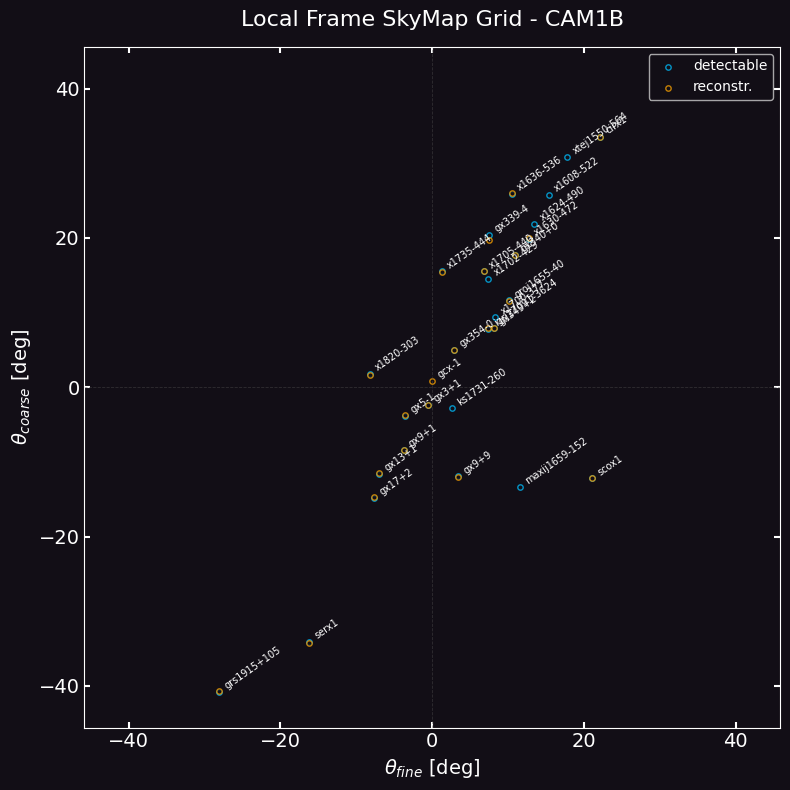

In [95]:
show_skyfield_map(
    camera=wfm,
    log=srcs_log,
    rec_log=log_cam,
    # save_to=f'{OUT_RESULTS_PATH}/detectable_srcs_inFoV_{log_cam.name}.pdf',
    camID=ID_CAMERA.upper(),
    figsize=(8, 8),
)

In [96]:
detector, _ = count(wfm, sdl_cam.DLdata)
true_sky = decode(wfm, detector)
varmap = variance(wfm, detector)

Subtracting ['scox1']...


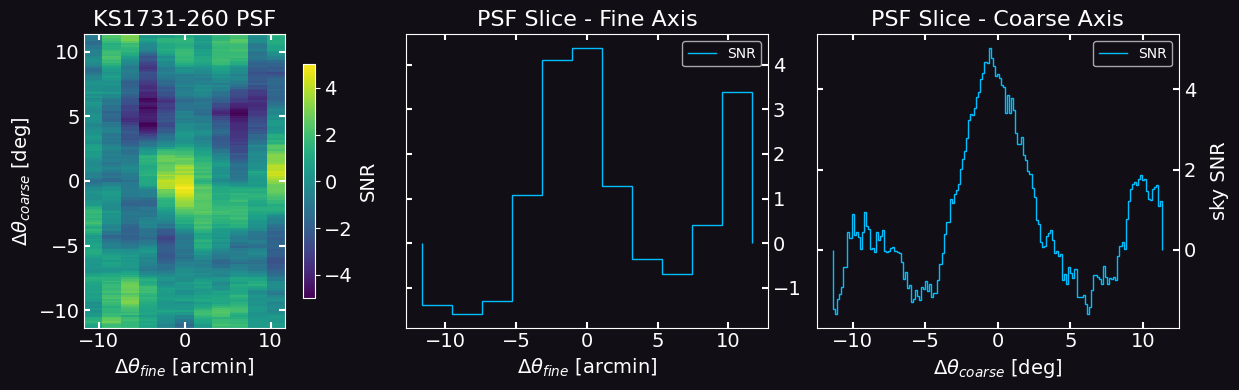

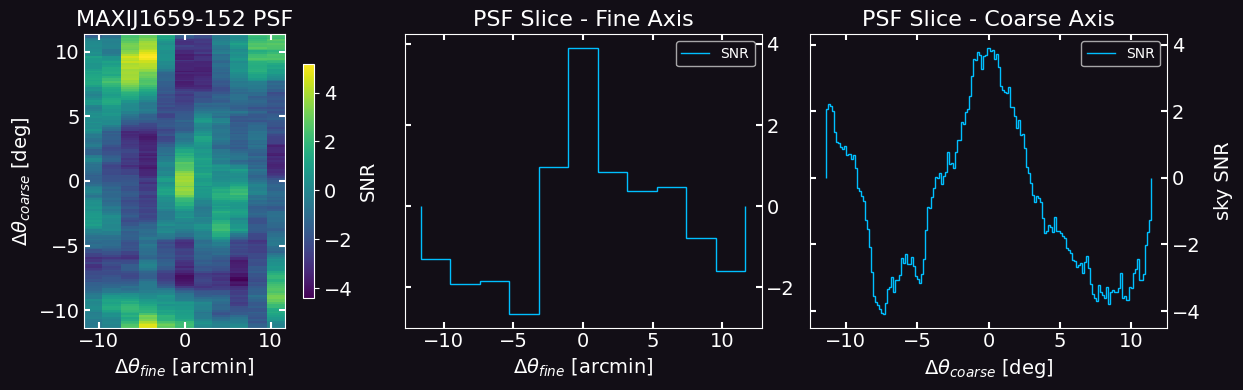

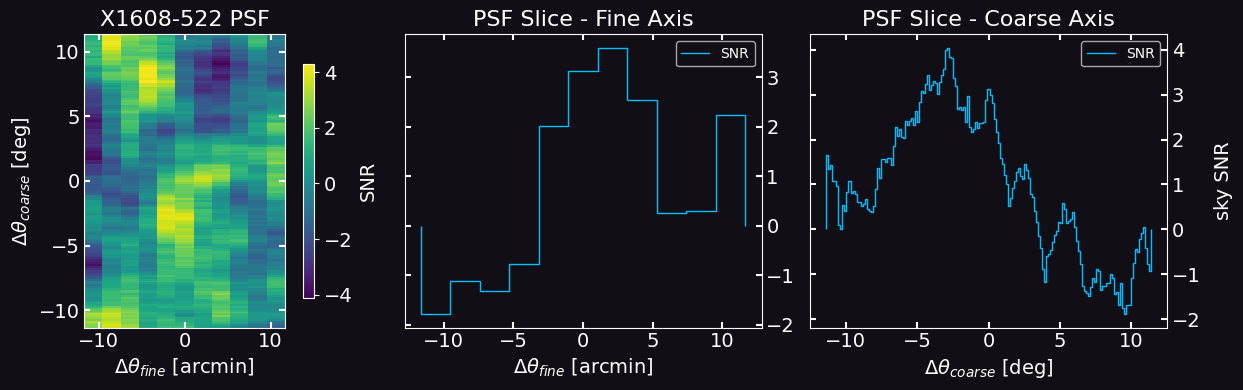

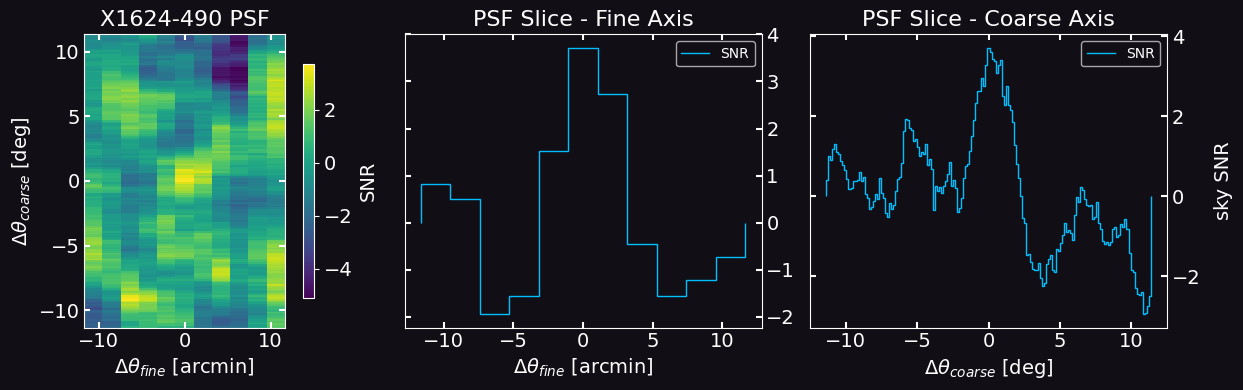

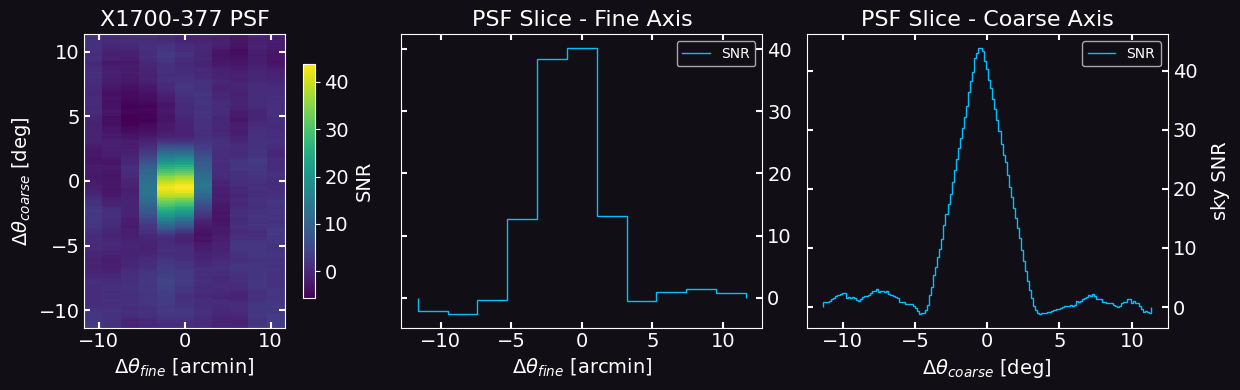

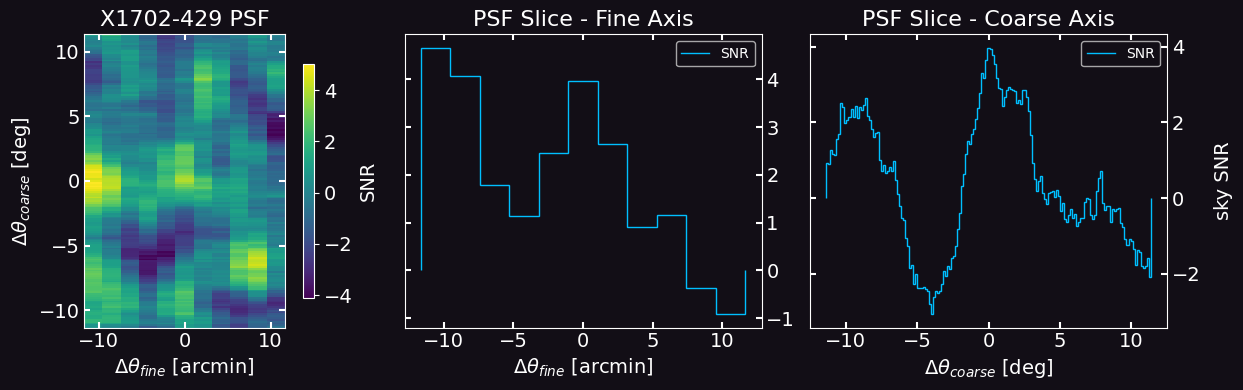

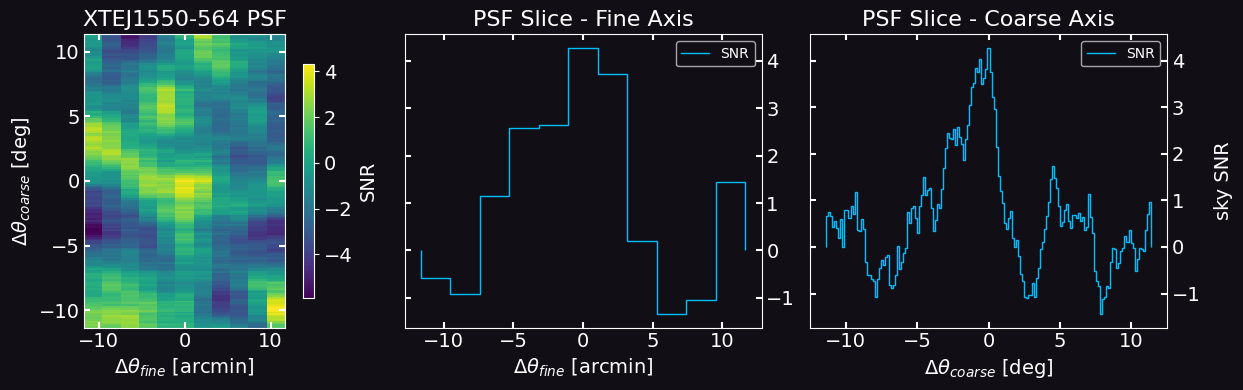

In [97]:
subtract_upto = 1

show_missing_srcs(
    camera=wfm,
    srcs_log=srcs_log,
    rec_log=log_cam,
    skymap=true_sky,
    varmap=varmap,
    crp=(80 * UPS_Y, 4 * (UPS_X - 1) + 1),
    figsize=(4.2 * 3 + 0.5, 4),
    subtract_upto=subtract_upto,
    skymodel_kws=dict(vignetting=VIGNETTING, psfy=PSFY),
)

In [98]:
# def show_missing_srcs(
#     camera: CodedMaskCamera,
#     srcs_log: Log,
#     rec_log: Log,
#     skymap: NDArray,
#     varmap: NDArray,
#     crp: tuple[int, int],
#     subtract_upto: Optional[int] = None,
#     save_to: Optional[str | Path] = None,           # NOTE: path to directory
#     frmt: str = 'pdf',
#     save_options: Optional[dict[str, Any]] = None,
#     skymodel_kws: Optional[dict[str, Any]] = None,
#     **fig_kws,
# ) -> None:
#     """
#     Displays non-detected source SNR levels.
#     """
#     title_fs, lbl_fs = 16, 14
#     dtx, dty = ds.pixels_angular_resolution(camera, verbose=False)

#     if subtract_upto is not None:
#         print(f'Subtracting {log_cam.log['ID'][:subtract_upto]}...')
#         skymap_ = subtract_previous(camera, rec_log, subtract_upto, skymap, **(skymodel_kws or {}))
#     else:
#         skymap_ = skymap
    
#     snrmap = snratio(skymap_, varmap)
    
#     for idx, srcID in enumerate(srcs_log.log['ID']):
#         if srcID not in rec_log.log['ID']:
#             sx, sy = map(lambda x: angle2shift(camera, x), (srcs_log.log['angle_x'][idx], srcs_log.log['angle_y'][idx]))
#             i, j = shift2pos(camera, sx, sy)
#             i, j = find_boxmax(skymap_, (i, j), boxsize=3 + int(2 * (camera.upscale_f.x - 1)))
#             sky_hm, snr_hm = map(lambda x: ds.crop(x, (i, j), crp, strict=False), (skymap_, snrmap))
#             xslice, yslice = get_slices(sky_hm, snr_hm)

#             fig, axs = plt.subplots(2, 3, tight_layout=True, **fig_kws)
#             axs = axs.flatten()

#             # ------------------------     PSFs     --------------------------
#             y_ext, x_ext = map(lambda s, dt: ((-0.5 - s // 2) * dt, (s - 0.5 - s // 2) * dt), sky_hm.shape, (dty, dtx))
#             y_ext = map(lambda x: x / 60, y_ext)
#             img_factory = {
#                 'origin': 'lower',
#                 'interpolation': 'none',
#                 'extent': [*x_ext, *y_ext],
#                 'aspect': 1.5,
#             }
#             axs[0].set_title(f'{srcID.upper()} PSF', fontsize=title_fs)
#             img = axs[0].imshow(sky_hm, cmap='viridis', **img_factory)
#             cbar = fig.colorbar(img, ax=axs[0], location='right', shrink=0.8, pad=0.05)
#             cbar.set_label('counts', fontsize=lbl_fs)
#             cbar.ax.tick_params(labelsize=lbl_fs)
#             axs[0].set_xlabel('$\\Delta\\theta_{fine}$ [arcmin]', fontsize=lbl_fs)
#             axs[0].set_ylabel('$\\Delta\\theta_{coarse}$ [deg]', fontsize=lbl_fs)

#             axs[3].set_title('Source SNR', fontsize=title_fs)
#             img = axs[3].imshow(snr_hm, cmap='viridis', **img_factory)
#             cbar = fig.colorbar(img, ax=axs[3], location='right', shrink=0.8, pad=0.05)
#             cbar.set_label('SNR', fontsize=lbl_fs)
#             cbar.ax.tick_params(labelsize=lbl_fs)
#             axs[3].set_xlabel('$\\Delta\\theta_{fine}$ [arcmin]', fontsize=lbl_fs)
#             axs[3].set_ylabel('$\\Delta\\theta_{coarse}$ [deg]', fontsize=lbl_fs)

#             # ------------------------     fine axis     ------------------------
#             x = dtx * set_phase(xslice[0])
#             axs[1].set_title('PSF Slice - Fine Axis', fontsize=title_fs)
#             axs[1].stairs(xslice[0], edges=x, edgecolor='DeepSkyBlue', label='counts')
#             axs[1].set_xlabel(xlabel='$\\Delta\\theta_{fine}$ [arcmin]', fontsize=lbl_fs)
#             axs[1].yaxis.tick_right()

#             axs[4].set_title('SNR Slice - Fine Axis', fontsize=title_fs)
#             axs[4].stairs(xslice[1], edges=x, edgecolor='DeepSkyBlue', label='SNR')
#             axs[4].set_xlabel(xlabel='$\\Delta\\theta_{fine}$ [arcmin]', fontsize=lbl_fs)
#             axs[4].yaxis.tick_right()

#             # ------------------------     coarse axis     ----------------------
#             x = dty * set_phase(yslice[0]) / 60
#             axs[2].set_title('PSF Slice - Coarse Axis', fontsize=title_fs)
#             axs[2].stairs(yslice[0], edges=x, edgecolor='DeepSkyBlue', label='counts')
#             axs[2].set_xlabel(xlabel='$\\Delta\\theta_{coarse}$ [deg]', fontsize=lbl_fs)
#             axs[2].set_ylabel(ylabel='sky counts', labelpad=10, fontsize=lbl_fs)
#             axs[2].yaxis.set_label_position('right')
#             axs[2].yaxis.tick_right()

#             axs[5].set_title('SNR Slice - Coarse Axis', fontsize=title_fs)
#             axs[5].stairs(yslice[1], edges=x, edgecolor='DeepSkyBlue', label='SNR')
#             axs[5].set_xlabel(xlabel='$\\Delta\\theta_{coarse}$ [deg]', fontsize=lbl_fs)
#             axs[5].set_ylabel(ylabel='sky SNR', labelpad=10, fontsize=lbl_fs)
#             axs[5].yaxis.set_label_position('right')
#             axs[5].yaxis.tick_right()

#             for ax in axs:
#                 ax.xaxis.set_ticks_position('both')
#                 ax.yaxis.set_ticks_position('both')
#                 ax.tick_params(which='both', direction='in', width=1.5, length=4 if 'major' else 2.5, labelsize=lbl_fs)
#             for idx in [1, 2, 4, 5]:
#                 axs[idx].legend(loc='best')
        
#             if save_to is not None:
#                 save_options_ = save_options or {}
#                 fig.savefig(f'{save_to}/non_detected_snrmap_{srcID.upper()}.{frmt}', **save_options_)
                
#             plt.show()

#     return